In [1]:
import pygeoinf as inf 
import numpy as np
from typing import List, Any
import matplotlib.pyplot as plt
from aux import GridSpace, WaterMassForwardOperator, create_spatial_covariance_matrix, create_point_measurement_operator

In [2]:
mat = np.array([[1, 2, 3, 4],
                [5, 6, 7, 8],
                [1, 1, 1, 1]])

number_of_measurements = 50
width = 40
height = 25

xs = np.random.randint(0, width, size=number_of_measurements).tolist()
ys = np.random.randint(0, height, size=number_of_measurements).tolist()

In [3]:
grid = GridSpace((height, width))

op1 = WaterMassForwardOperator(grid, mat).as_linear_operator()
op2 = create_point_measurement_operator(xs, ys, op1.codomain)
forward_operator = op2 @ op1

single_variable_measurement_space = forward_operator.codomain.subspaces[0]
data_error_measure = inf.GaussianMeasure.from_standard_deviation(single_variable_measurement_space, 0.001)
joint_data_error_measure = inf.GaussianMeasure.from_direct_sum([data_error_measure] * forward_operator.codomain.number_of_subspaces)

forward_problem = inf.LinearForwardProblem(forward_operator, data_error_measure=joint_data_error_measure)

In [4]:
prior_covariance_matrix = create_spatial_covariance_matrix(grid.shape, 0.3, 2.0)
prior_expectation = np.full(grid.shape,  0.25)
prior_measure = inf.GaussianMeasure.from_covariance_matrix(grid, prior_covariance_matrix, expectation=prior_expectation)
joint_prior_measure = inf.GaussianMeasure.from_direct_sum([prior_measure] * forward_operator.domain.number_of_subspaces)

true_model, data = forward_problem.synthetic_model_and_data(joint_prior_measure)

# Set the last component of data to an array of ones as a conservation of mass constraint
data[-1] = np.ones(number_of_measurements)

inversion = inf.LinearBayesianInversion(forward_problem, joint_prior_measure)
solver = inf.CholeskySolver(galerkin=True)
posterior = inversion.model_posterior_measure(data, solver)

ValueError: Covariance matrix is not non-negative

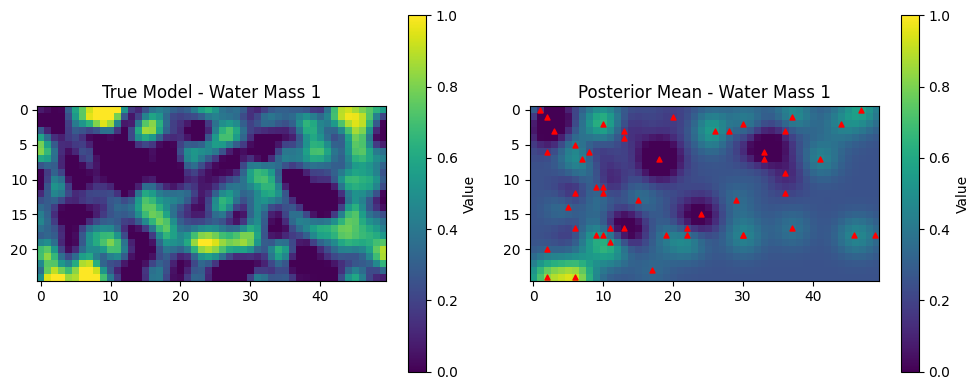

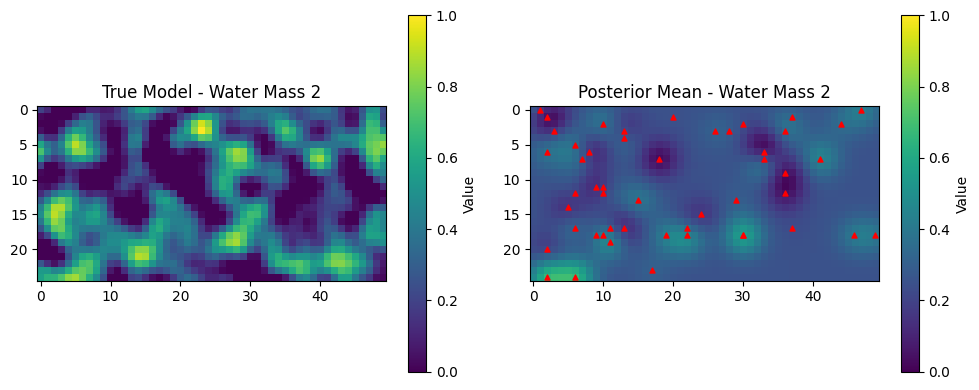

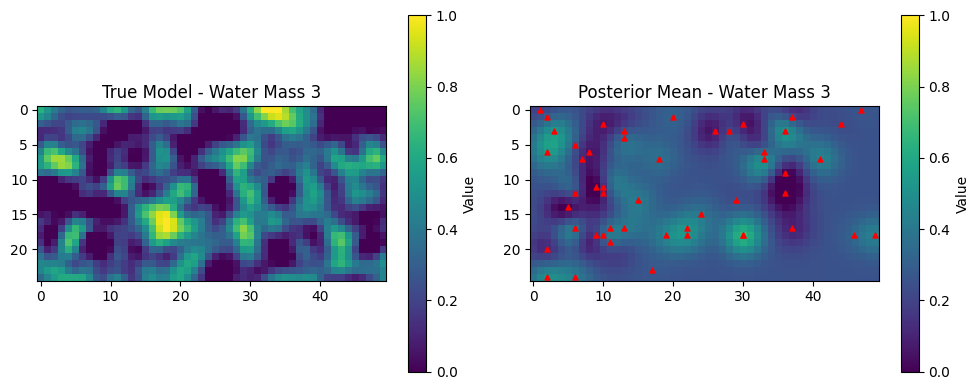

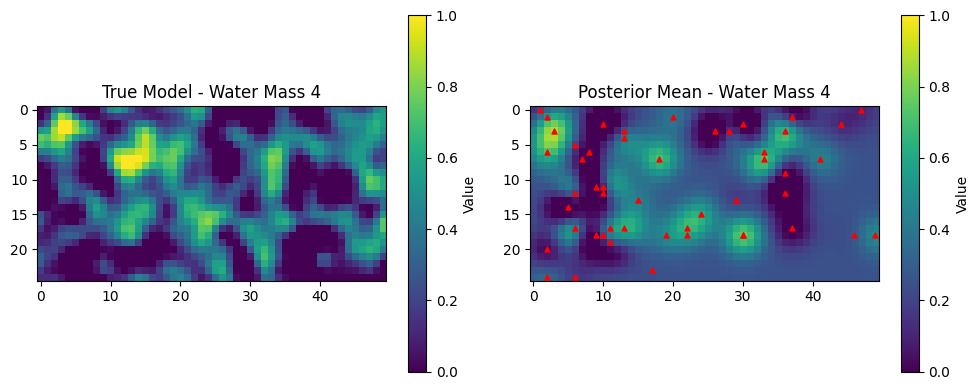

In [ ]:
# Plot the results - each row is a water mass, and show true vs posterior mean
for i in range(mat.shape[1]):
    plt.figure(figsize=(10, 4))
    
    # True model
    plt.subplot(1, 2, 1)
    plt.title(f"True Model - Water Mass {i+1}")
    plt.imshow(true_model[i], cmap='viridis', vmin=0, vmax=1)
    plt.colorbar(label='Value')
    
    # Posterior mean
    plt.subplot(1, 2, 2)
    plt.title(f"Posterior Mean - Water Mass {i+1}")
    plt.imshow(posterior.expectation[i], cmap='viridis', vmin=0, vmax=1)
    plt.colorbar(label='Value')

    # Plot where the point measurements were taken
    plt.scatter(xs, ys, c='red', marker='^', s=13, label='Measurement Points')
    
    plt.tight_layout()